# Hessian and Variation

The Herman–Kluk pre-factor requires the monodromy matrix $M_t = \frac{\partial (Q_t, P_t)}{\partial (Q_0, P_0)}$ in the physical space.

PySCIVR computes it by propagating the variation along the trajectory in the redundant Cartesian coordinates with the linearized SHAKE/RATTLE equations, which require the Hessian of the potential at each step.

In this tutorial, the ro-vibrational trajectory of H2 (`h2_rovib_pi2_traj.npz`) from the previous tutorial is used:
| Redundant space | Integrator | Physical space |
|---|---|---|
| Cartesian (6 DOFs) with 3 constraints (3 translations) | `ShakeRattle` | bond length $r$, polar $\theta$ and azimuthal angle $\phi$ |

We first compute the monodromy matrix with the full Hessian at every step, and then show how to reduce the cost of the Hessian evaluation.

In [1]:
# import necessary libraries

import numpy as np
import matplotlib.pyplot as plt
 
from pyscivr.coordinates import InternalCoordinates
from pyscivr.hessian import eval_hess_active, interpolate_hessian, projected_hessian
from pyscivr.potentials import H2SplinePotential
from pyscivr.save import load_hessian, load_trajectory, save_hessian
from pyscivr.units import FemtoSec
from pyscivr.variations import make_jacobi_func, make_vari_propagator, propagate_variation, to_internal

## Set systems

The system, the constraints `coord_const` and the curvilinear coordinates `coord_all` are the same as in the previous tutorial.

The active (physical) coordinates are the polar and azimuthal angles.

In [2]:
mass = np.array([1.008, 1.008])  # [amu]
r_e = 0.74160392                 # equilibrium bond length [Angs]
posi_ref = np.array([[-r_e / 2, 0.0, 0.0], [r_e / 2, 0.0, 0.0]])

calc = H2SplinePotential()

coord_const = InternalCoordinates(posi_ref, mass)
coord_const.add_translation()
coord_const.build()

coord_all = InternalCoordinates(posi_ref, mass)
coord_all.add_translation()
coord_all.add_polar(0, 1)
coord_all.add_azimuthal(0, 1)
coord_all.add_bond(0, 1)
coord_all.build()

active_idx = np.array([coord_all.find_coordinate(kind, (0, 1))[0] for kind in ("bond", "polar", "azimuthal")])

print('active_idx =', active_idx)

Build complete: 3 coordinates
Build complete: 6 coordinates
active_idx = [3 4 5]


## Load the trajectory

In [3]:
traj = load_trajectory("h2_rovib_pi2_traj.npz", coord_const=coord_const)
posi, mome, lam, mu, dt = traj["posi"], traj["mome"], traj["lam"], traj["mu"], traj["dt"]
values  = coord_all.get_value_batch(posi)
B = coord_all.get_const_grad_batch(posi)

n_step = len(posi)
t_fs = dt / FemtoSec * np.arange(n_step)

## Monodromy matrix with the full Hessian

`H2SplinePotential` supports the analytical Hessian, so we first use the full $3N \times 3N$ Hessian at every step. The monodromy matrix is computed in the following steps:

1. `make_jacobi_func` makes the Jacobians between the redundant and physical spaces.
2. The initial variation is set to $J_{\text{rev}}(0)$, which maps the physical space to the redundant space.
3. `propagate_variation` propagates the variation in the redundant space using the Hessians and the Lagrange multipliers.
4. `to_internal` transforms the variation to the physical space by $J(t)$, giving the monodromy matrix $M_t = J(t) M_t^{\text{red}} J_{\text{rev}}(0)$.

The monodromy matrix of a Hamiltonian system is symplectic. If it is computed correctly, $M_t$ should satisfy

$$
M_t^T \Omega M_t = \Omega, \quad
\Omega = \begin{pmatrix} 0 & I \\ -I & 0 \end{pmatrix},
$$

where $I$ is the $m \times m$ identity matrix. `to_internal` returns the symplectic error

$$
\epsilon_t = \max \left| M_t^T \Omega M_t - \Omega \right|,
$$

which is used to check the consistency of the calculation.

As shown in the previous tutorial, the singular points can be detected by the condition number of $B$.
Since the transformation to the physical space does not exist at the singular points, the elements of $M_t$
become large in their vicinity, and the symplectic error $\epsilon_t$ may increase due to the loss of numerical precision.

See [`pyscivr.variations`](https://tsumura-m.github.io/PySCIVR/pyscivr.variations.html) for details.

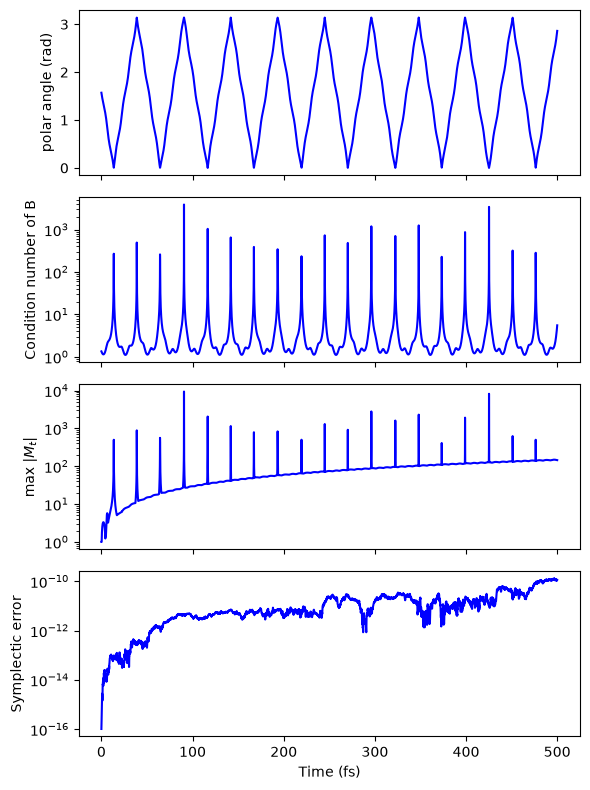

In [4]:
_, jacobi_rev_func, _, monodromy_func = make_jacobi_func(coord_all, active_idx)
J_rev_init = np.asarray(jacobi_rev_func(posi[0], mome[0])) # (6N, 2m)
vari_propagator = make_vari_propagator(coord_const, dt)

hess_full = calc.hessian(posi) # (T, 3N, 3N)
vari_full = propagate_variation(vari_propagator, posi, mome, lam, mu, hess_full, J_rev_init)
_, _, mono_full, symp_err_full = to_internal(monodromy_func, posi, mome, vari_full) # mono_full : (T, 2m, 2m)

fig, ax = plt.subplots(4, 1, sharex=True, figsize=(6, 8))

ax[0].set_ylabel("polar angle (rad)")
ax[0].plot(t_fs, values[:, active_idx[1]], color='blue')
ax[1].semilogy(t_fs, np.linalg.cond(B), color='blue')
ax[1].set_ylabel("Condition number of B")
ax[2].semilogy(t_fs, np.max(np.abs(mono_full), axis=(1, 2)), color='blue')
ax[2].set_ylabel("max |$M_t$|")
ax[3].semilogy(t_fs, symp_err_full, color='blue')
ax[3].set_ylabel("Symplectic error")
ax[3].set_xlabel("Time (fs)")
plt.tight_layout()
plt.show()

At the singular points, where the condition number of $B$ diverges, the transformation to the physical space does not exist. As the trajectory approaches these points, the elements of $M_t$ therefore diverge, which can lead to numerical errors in the symplectic condition.

In this trajectory, the time steps happen to approach the singular points only to the extent that this effect is negligible, and the symplectic error remains small.

Since the SC-IVR calculation relies on the symplectic condition, the symplectic error should always be checked, and only the steps where it is small can be used (see the next tutorial).

## Reducing the cost of the Hessian

The full Hessian at every step is expensive for ab initio potentials: analytical Hessians are often unavailable, and the numerical Hessian requires $2 \times 3N$ force evaluations per step.

The Hessian evaluation therefore becomes the bottleneck of a straightforward SC-IVR calculation, costing $O(N)$ times more than the trajectory itself.

PySCIVR reduces this cost in two ways:

- **Only the active directions**: the propagation only needs the Hessian projected onto the active coordinates,
  which is obtained from $\nabla^2 V A_A$ with $A_A \equiv \partial q / \partial Q_A$.
  `eval_hess_active` computes it by central differences of the forces along the $m$ columns of $A_A$,
  requiring $2m$ force evaluations per step instead of $2 \times 3N$.
- **Only at selected steps**: the projected Hessian is evaluated every $I$ steps and interpolated
  to all steps by cubic spline.

As a result, the number of force evaluations for the Hessian along a trajectory of $T$ steps is reduced
from $6NT$ to $\frac{2mT}{I}$, **independent of the number of atoms $N$**:

| | Number of Force evaluations | Butane torsion ($N = 14$, $m = 1$, $I = 20$, $T=10000$) |
|---|---|---|
| Trajectory | $T$ | $10000$ |
| Full numerical Hessian at every step | $6NT$ | $840000$ |
| Projected Hessian at selected steps | $\frac{2mT}{I}$ | $1000$ |

For the torsion of butane, the cost of the Hessian is reduced by a factor of 840,
and becomes only 10 % of that of the trajectory.

Since $A_A$ is the active component of the inverse of $B$, it is not defined at the singular points. The projected Hessian therefore should not be evaluated in their vicinity, which is detected by the condition number of $B$; these steps are filled by the interpolation together with the skipped steps.

The interval $I$ should be chosen sufficiently small compared with the period of the fastest motion in the active coordinates, and its convergence should be checked as shown below.

See [`pyscivr.hessian`](https://tsumura-m.github.io/PySCIVR/pyscivr.hessian.html) for details.

First, we exclude the points near singularities to avoid numerical instability. 
Here, points where the condition number of B exceeds 100 are excluded.

In [5]:
x = posi.reshape(n_step, -1) # (T, 3N)
cond_B = np.linalg.cond(np.asarray(coord_all.get_const_grad_batch(x)))
steps_valid = np.where(cond_B <= 1e2)[0]
print(f"{n_step - len(steps_valid)} of {n_step} steps are near the singular points.")

43 of 5001 steps are near the singular points.


Compare numerical projected Hessians and analytical one.

In [6]:
steps = steps_valid[::5] # take every 5th step of the valid steps
 
KA, AA, BA = eval_hess_active(calc, coord_all, active_idx, posi, steps, eps=1e-6)

K_analytical = calc.hessian(posi[steps]) # (S, 3N, 3N)
KA_analytical = K_analytical @ AA # (S, 3N, m)

print(f"max |numerical - analytical| = {np.max(np.abs(KA - KA_analytical)):.3e}")

max |numerical - analytical| = 4.655e-09


`KA` ($\nabla^2 V A_A$) is converted into the projected Hessian ($\mathfrak{P}^T(\nabla^2 V A_A) B_A, \quad \mathfrak{P} \equiv A_A B_A$) via `projected_hessian` function and used in subsequent calculations.

In [7]:
hess_proj = projected_hessian(KA, AA, BA)

## Save and load the Hessians

`save_hessian` stores the Hessians as $\nabla^2 V A_A$ of shape `(S, 3N, m)` to reduce the file size.
`load_hessian` restores the projected Hessians, and interpolates them to all steps if `n_step` is given.

See [`pyscivr.save`](https://tsumura-m.github.io/PySCIVR/pyscivr.save.html) for details.

In [8]:
save_hessian("h2_rovib_pi2_hess.npz", steps, hess_proj, posi, coord_all, active_idx)

_, hess_loaded = load_hessian("h2_rovib_pi2_hess.npz", coord_all, posi)
print(f"max |loaded - saved| = {np.max(np.abs(hess_loaded - hess_proj)):.3e}")

_, hess_interp = load_hessian("h2_rovib_pi2_hess.npz", coord_all, posi, n_step=n_step)
print(hess_interp.shape)  # (T, 3N, 3N)

max |loaded - saved| = 2.842e-14
(5001, 6, 6)


## Effect of the interpolation on the monodromy matrix

The numerical Hessians are evaluated every `interval` steps (excluding the vicinity of the singular points) and interpolated, and the resulting monodromy matrices are compared with that from the full Hessian.

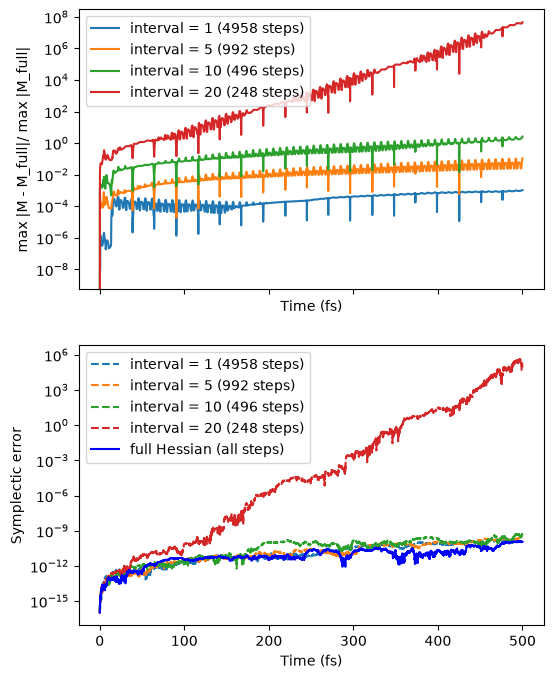

In [9]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(6, 8))

for interval in [1, 5, 10, 20]:
    steps = steps_valid[::interval]
    HA, AA, BA = eval_hess_active(calc, coord_all, active_idx, posi, steps)
    hess = interpolate_hessian(steps, projected_hessian(HA, AA, BA), n_step) 
    vari = propagate_variation(vari_propagator, posi, mome, lam, mu, hess, J_rev_init)
    _, _, mono, symp_err = to_internal(monodromy_func, posi, mome, vari)

    deviation = np.max(np.abs(mono - mono_full), axis=(1, 2)) / np.max(np.abs(mono_full), axis=(1, 2))
    ax[0].semilogy(t_fs, deviation, label=f"interval = {interval} ({len(steps)} steps)")
    ax[1].semilogy(t_fs, symp_err, label=f"interval = {interval} ({len(steps)} steps)", linestyle='dashed')

ax[1].plot(t_fs, symp_err_full, color='blue', label="full Hessian (all steps)")
ax[0].set_xlabel("Time (fs)")
ax[0].set_ylabel("max |M - M_full|/ max |M_full|")
ax[1].set_xlabel("Time (fs)")
ax[1].set_ylabel("Symplectic error")
ax[0].legend()
ax[1].legend()
plt.show()

The relative deviation from the monodromy matrix with the full Hessian decreases systematically
as the interval of the Hessian evaluation is reduced:

- `interval = 1` (about 80 evaluations per vibrational period of about 8 fs): below 0.1 %.
- `interval = 5` (about 16 evaluations per period): a few %.
- `interval = 10` (about 8 evaluations per period): comparable to the monodromy matrix itself at long times.
- `interval = 20` (about 4 evaluations per period): the cubic spline cannot follow the vibration,
  and the deviation grows exponentially.

The symplectic error remains as small as that with the full Hessian except for `interval = 20`,
where the precision is lost as the elements of $M_t$ grow exponentially.
The symplectic error thus detects only severe failures, and is not sufficient to judge the accuracy of the Hessian.

Therefore, the interval should be chosen so that the fastest motion in the active coordinates is sampled
sufficiently (here, at least about 16 evaluations per period for an accuracy of a few %),
and its convergence should be checked by comparing the results with different intervals.